# 04. Evaluation, Uplift/Qini Curves, and Visualizations
**Team Member**: Project Lead & Evaluation (Member 4)
**Objective**: Generate Qini / Uplift curves, compute AUUC scores, plot ITE distributions, and summarize executive findings for presentation slides.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.data.synthetic import generate_synthetic_data
from src.models.dml_estimator import DoubleMLEstimator
from src.evaluation.metrics import compute_uplift_curve, compute_qini_score, summarize_causal_metrics
from src.evaluation.visualizations import plot_qini_curve, plot_ite_distribution, plot_budget_allocation_summary
from src.optimization.policy_allocator import compare_allocation_policies
from src.utils.config import Config

# Setup data and run DML model
df = generate_synthetic_data(n_samples=5000, random_state=42)
features = ["Age", "PriorSpend", "VisitFrequency", "LoyaltyScore"]
dml = DoubleMLEstimator(n_splits=3, nuisance_type="random_forest", backend="native").fit(df[features], df["Discount"], df["Sales"])
df["Estimated_ITE"] = dml.ite_estimates_
print("DML pipeline complete. Proceeding to evaluation.")

[2026-10-21 15:55:05] [INFO] [DoubleMLEstimator]: Fitting DML Estimator using backend 'native' and 'random_forest' nuisances...


[2026-10-21 15:55:06] [INFO] [DoubleMLEstimator]: Native DML fit complete: ATE = 31.092 +/- 1.130


DML pipeline complete. Proceeding to evaluation.


In [2]:
# Compute Summary Metrics
metrics = summarize_causal_metrics(df["Estimated_ITE"].values, true_ite=df["TrueITE"].values)
for k, v in metrics.items():
    print(f"{k}: {v:.3f}")

Mean_Estimated_ITE: 31.092
Std_Estimated_ITE: 7.511
Median_Estimated_ITE: 30.814
Top_10_Percent_Mean_ITE: 44.770
Min_ITE: 10.895
Max_ITE: 62.792
GroundTruth_RMSE: 5.524
GroundTruth_MAE: 4.456
GroundTruth_Correlation: 0.696


Normalized Qini Score (AUUC): 6183.16


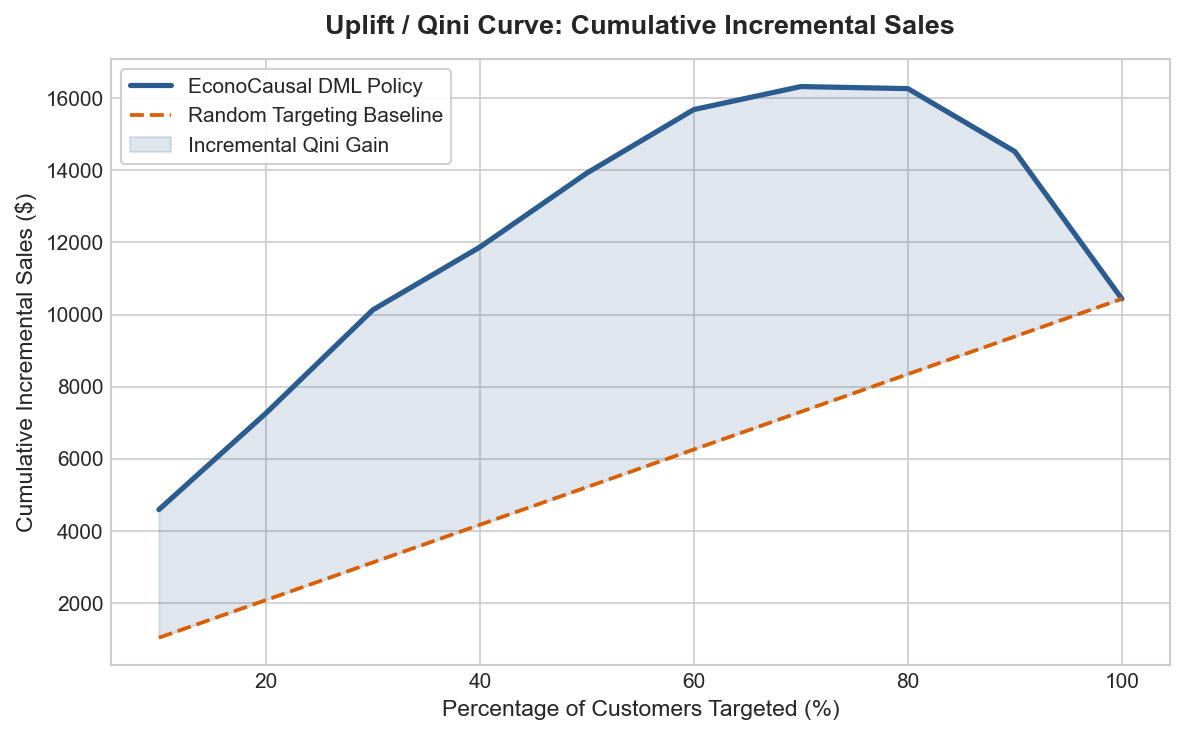

In [3]:
# Generate & Plot Qini Curve
qini_df = compute_uplift_curve(df["Sales"].values, df["Discount"].values, df["Estimated_ITE"].values)
qini_score = compute_qini_score(qini_df)
print(f"Normalized Qini Score (AUUC): {qini_score:.2f}")
fig_qini = plot_qini_curve(qini_df, save_path=Config.FIGURES_DIR / "qini_curve.png")
plt.show()

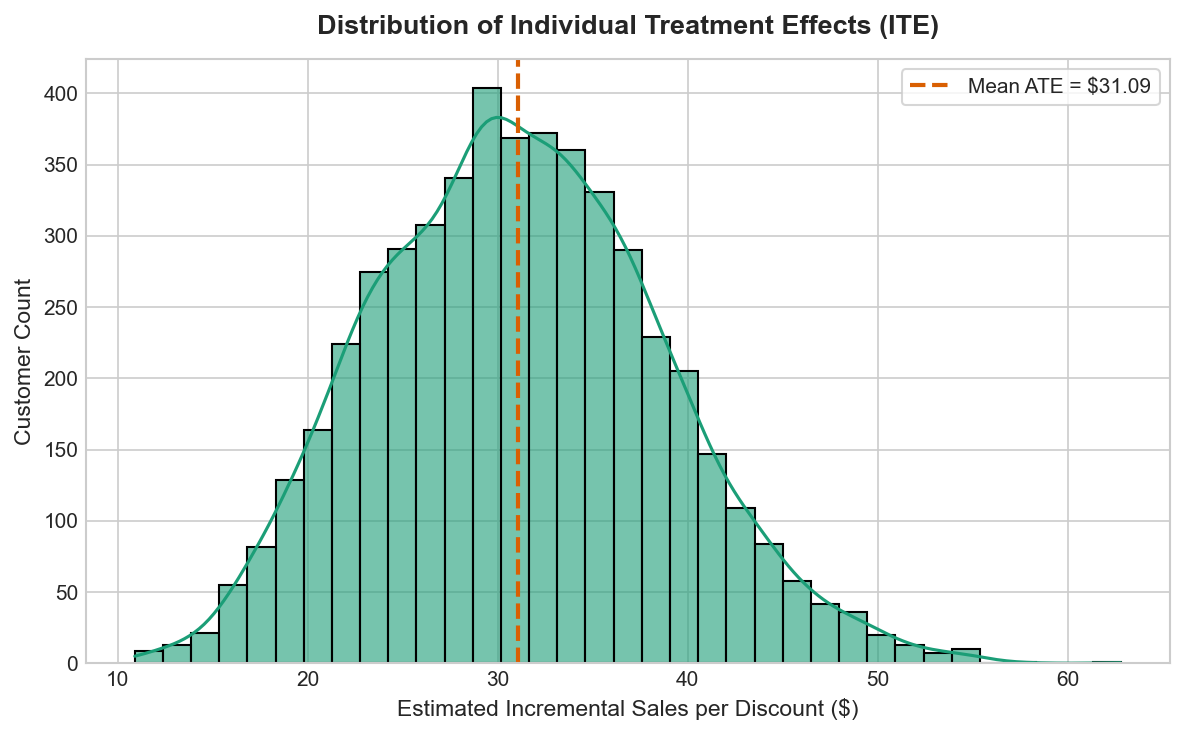

In [4]:
# Plot ITE Distribution
fig_ite = plot_ite_distribution(df["Estimated_ITE"].values, save_path=Config.FIGURES_DIR / "ite_distribution.png")
plt.show()